**Downloading Data set: Arlreasy Packed with Keras Datasets**

In [30]:
from keras.datasets import reuters
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)


In [2]:
len(train_data)

8982

In [3]:
len(test_data)

2246

In [5]:
print("Total Dataset:", len(train_data) + len(test_data))


Total Dataset: 11228


**Data Labels**

In [8]:
train_labels

array([ 3,  4,  3, ..., 25,  3, 25])

**Cheking Class Balancing**

In [19]:
from tensorflow.keras import datasets
import pandas as pd
labels = pd.DataFrame({"class_name": datasets.reuters.get_label_names(),'Counts':pd.Series(train_labels).value_counts() }).sort_index()
labels

,class_name,Counts
0,crude,55
1,acq,432
2,ship,74
3,cocoa,3159
4,grain,1949
5,orange,17
6,gnp,48
7,pet-chem,16
8,money-supply,139
9,sugar,101


**Unique Vocabulary of the data set**

In [20]:
word_index = reuters.get_word_index()
len(word_index)

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


30979

**Encoding the Data Already given in numerical vectors**

In [47]:
import numpy as np
def vectorize_sequences(sequences, dimension=10000):
  results = np.zeros((len(sequences), dimension))
  for i, sequence in enumerate(sequences):
    results[i, sequence] = 1.
  return results
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

**Encoding the labels of the news: using to categoricalmethod from keras **

In [48]:
from keras.utils import to_categorical
one_hot_train_labels = to_categorical(train_labels)
one_hot_test_labels = to_categorical(test_labels)

In [49]:
one_hot_train_labels.shape

(8982, 46)

In [63]:
from keras import models
from keras import layers
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', input_shape=(10000,)))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(46, activation='softmax'))

In [64]:
model.compile(optimizer='rmsprop',loss='categorical_crossentropy',metrics=['accuracy'])

**Breaking Training Data into Training And Validation Data Sets**

In [65]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]

In [66]:
history = model.fit(partial_x_train,partial_y_train,epochs=20,batch_size=512,validation_data=(x_val, y_val))

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.4977 - loss: 2.7725 - val_accuracy: 0.6020 - val_loss: 1.8967
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6659 - loss: 1.5910 - val_accuracy: 0.6870 - val_loss: 1.4087
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7365 - loss: 1.2163 - val_accuracy: 0.7320 - val_loss: 1.1998
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7816 - loss: 1.0025 - val_accuracy: 0.7560 - val_loss: 1.0890
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8216 - loss: 0.8332 - val_accuracy: 0.7830 - val_loss: 1.0173
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8479 - loss: 0.6974 - val_accuracy: 0.7900 - val_loss: 0.9601
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8701 - loss: 0.5906 - val_accuracy: 0.8110 - val_loss: 0.9038
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8900 - loss: 0.5011 - val_accuracy: 0.8120 - 

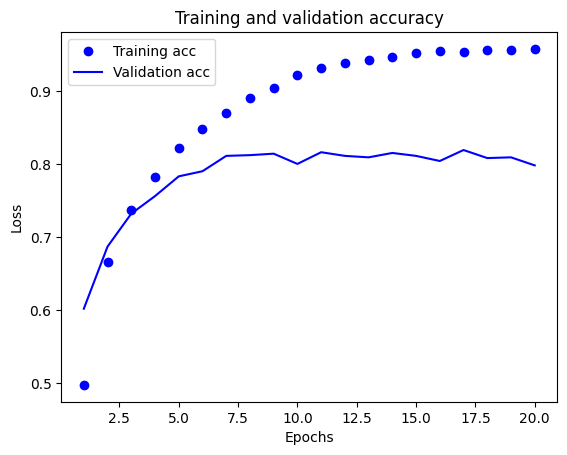

In [68]:
plt.clf()
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(acc) + 1)
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

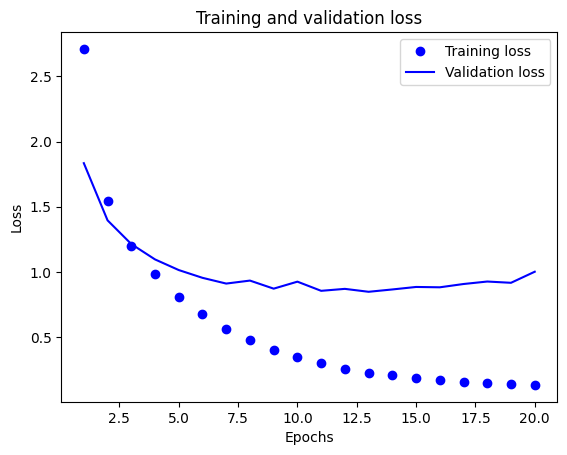

In [54]:
import matplotlib.pyplot as plt
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [69]:
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', input_shape=(10000,)))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(46, activation='softmax'))

model.compile(optimizer='rmsprop',loss='categorical_crossentropy',metrics=['accuracy'])

model.fit(partial_x_train,partial_y_train,epochs=11,batch_size=512,validation_data=(x_val, y_val))


Epoch 1/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.5004 - loss: 2.7316 - val_accuracy: 0.6050 - val_loss: 1.8281
Epoch 2/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6753 - loss: 1.5564 - val_accuracy: 0.6860 - val_loss: 1.3854
Epoch 3/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7370 - loss: 1.2070 - val_accuracy: 0.7330 - val_loss: 1.2133
Epoch 4/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7816 - loss: 0.9990 - val_accuracy: 0.7560 - val_loss: 1.1003
Epoch 5/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8158 - loss: 0.8397 - val_accuracy: 0.7780 - val_loss: 1.0132
Epoch 6/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8477 - loss: 0.7062 - val_accuracy: 0.8040 - val_loss: 0.9650
Epoch 7/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8736 - loss: 0.5995 - val_accuracy: 0.8060 - val_loss: 0.9120
Epoch 8/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8951 - loss: 0.5067 - val_accuracy: 0.8040 - 

In [70]:
results = model.evaluate(x_test, one_hot_test_labels)

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7898 - loss: 0.9397
